<a href="https://colab.research.google.com/github/aldanamontagut-stack/StatUQ_Project1/blob/main/StatUQ_Project1_StudentFramework.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project 1: Analysis of pollutant concentration in the estuary of a river

### Initial framework for students

**The statements in bold represent required actions or content that users need to provide.**

# Part 1. Visual inspection and qualitative analysis

This part uses only the dataset `pollutant_training_data.npz`.

### Preprocess

**User is required to upload the file** `pollutant_training_data.npz`.

In [5]:
#@title Load training dataset {display-mode: "form"}

from pathlib import Path
import sys

import matplotlib.pyplot as plt
import matplotlib.tri as mtri
import numpy as np
import pandas as pd
from IPython.display import display

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titlesize": 11,
})


def locate_or_upload(filename):
    current = Path.cwd()

    candidates = []

    for root in [
        current,
        *current.parents,
    ]:
        candidates.extend([
            root / filename,
            root / "Data" / filename,
            root / "pollutant_datasets" / filename,
        ])

    for candidate in candidates:
        if candidate.is_file():
            return candidate.resolve()

    try:
        from google.colab import files as colab_files
    except ImportError:
        raise FileNotFoundError(
            f"Could not find {filename}. "
            "Place it beside the notebook or "
            "inside a Data/ directory."
        ) from None

    print(f"Upload {filename}")

    uploaded = colab_files.upload()

    if filename not in uploaded:
        raise FileNotFoundError(
            "The uploaded file must be named exactly "
            f"{filename}."
        )

    target = current / filename

    target.write_bytes(
        uploaded[filename]
    )

    return target.resolve()


def read_archive(filename):
    path = locate_or_upload(filename)

    with np.load(
        path,
        allow_pickle=False,
    ) as archive:
        required_variables = {
            "coordinates",
            "triangles",
            "mu",
            "concentration",
        }

        missing_variables = (
            required_variables
            - set(archive.files)
        )

        if missing_variables:
            raise KeyError(
                f"{filename} is missing: "
                + ", ".join(
                    sorted(missing_variables)
                )
            )

        result = {
            name: archive[name].copy()
            for name in archive.files
        }

    return path, result


# ---------------------------------------------------------
# Load only the training dataset
# ---------------------------------------------------------

TRAINING_FILE, training_data = read_archive(
    "pollutant_training_data.npz"
)


coordinates = training_data[
    "coordinates"
]

triangles = training_data[
    "triangles"
].astype(
    np.int64
)

mu_training = training_data[
    "mu"
].astype(
    float
)

concentration_training = training_data[
    "concentration"
].astype(
    float
)


# ---------------------------------------------------------
# Verify the training data
# ---------------------------------------------------------

n_nodes = len(
    coordinates
)

assert coordinates.shape == (
    n_nodes,
    2,
)

assert (
    triangles.ndim == 2
    and triangles.shape[1] == 3
)

assert triangles.min() >= 0

assert triangles.max() < n_nodes

assert concentration_training.shape == (
    len(mu_training),
    n_nodes,
)

assert np.isfinite(
    concentration_training
).all()

assert np.all(
    concentration_training > 0.0
)


# ---------------------------------------------------------
# Construct the triangular mesh representation
# ---------------------------------------------------------

triangulation = mtri.Triangulation(
    coordinates[:, 0],
    coordinates[:, 1],
    triangles,
)


# ---------------------------------------------------------
# Read the parameters of the observation-noise model
# ---------------------------------------------------------

sigma_epsilon = float(
    training_data[
        "sigma_epsilon"
    ]
)

s_epsilon = float(
    training_data[
        "s_epsilon"
    ]
)

c_min = float(
    training_data[
        "c_min"
    ]
)


# ---------------------------------------------------------
# Summary
# ---------------------------------------------------------

print(
    "Training file:",
    TRAINING_FILE,
)

print(
    f"Mesh: {n_nodes:,} nodes; "
    f"{len(triangles):,} triangles"
)

print(
    "Training inputs:",
    mu_training,
)

print(
    "Training concentration shape:",
    concentration_training.shape,
)

print(
    f"sigma_epsilon={sigma_epsilon:g}; "
    f"s_epsilon={s_epsilon:.8f}"
)

Upload pollutant_training_data.npz


Saving pollutant_training_data.npz to pollutant_training_data.npz
Training file: /content/pollutant_training_data.npz
Mesh: 3,745 nodes; 6,906 triangles
Training inputs: [10. 12. 14. 16. 18. 20. 22. 24. 26. 28. 30.]
Training concentration shape: (11, 3745)
sigma_epsilon=0.05; s_epsilon=0.04996879


In [6]:
#@title Concentration maps {display-mode: "form"}

import ipywidgets as widgets

try:
    from google.colab import output
    output.enable_custom_widget_manager()
except ImportError:
    pass


def plot_training_pair(index_left, index_right):
    values_left = concentration_training[index_left]
    values_right = concentration_training[index_right]
    common_maximum = max(values_left.max(), values_right.max())

    fig, axes = plt.subplots(
        1, 2, figsize=(14, 5), sharex=True, sharey=True,
        constrained_layout=True,
    )
    for ax, values, index in zip(
        axes,
        [values_left, values_right],
        [index_left, index_right],
    ):
        artist = ax.tripcolor(
            triangulation, values, shading="gouraud", cmap="viridis",
            vmin=0.0, vmax=common_maximum,
        )
        ax.set(
            title=rf"Noisy concentration, $\mu={mu_training[index]:g}$",
            xlabel="x", ylabel="y", aspect="equal",
        )
        ax.grid(False)
    fig.colorbar(artist, ax=axes, label="Concentration", shrink=0.82)
    plt.show()
    plt.close(fig)


pair_left = widgets.SelectionSlider(
    options=[(f"{value:g}", index) for index, value in enumerate(mu_training)],
    value=0, description="Left panel μ:", continuous_update=False,
    layout=widgets.Layout(width="650px"),
    style={"description_width": "150px"},
)
pair_right = widgets.SelectionSlider(
    options=[(f"{value:g}", index) for index, value in enumerate(mu_training)],
    value=len(mu_training) - 1, description="Right panel μ:",
    continuous_update=False, layout=widgets.Layout(width="650px"),
    style={"description_width": "150px"},
)
pair_output = widgets.interactive_output(
    plot_training_pair,
    {"index_left": pair_left, "index_right": pair_right},
)
display(pair_left, pair_right, pair_output)


SelectionSlider(continuous_update=False, description='Left panel μ:', layout=Layout(width='650px'), options=((…

SelectionSlider(continuous_update=False, description='Right panel μ:', index=10, layout=Layout(width='650px'),…

Output()

Minimum difference: -0.2957
Maximum difference: 0.7108
Mean difference:    0.3048


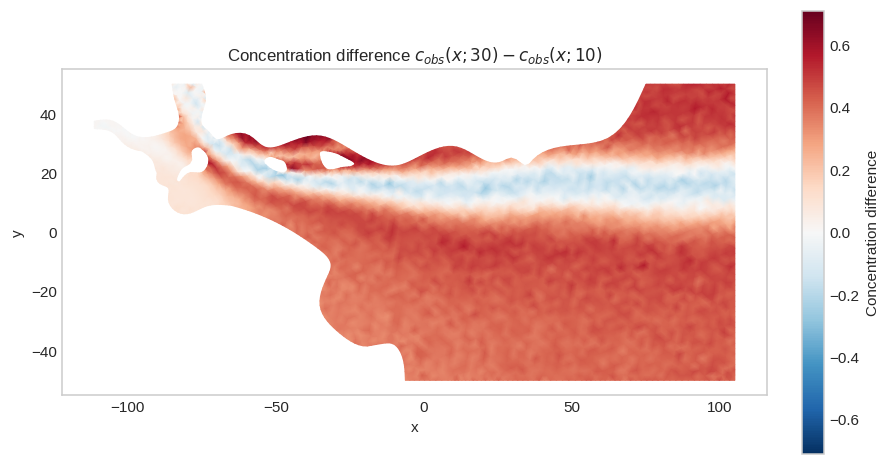

In [7]:
#@title Discrepancy map and physical interpretation {display-mode: "form"}

# ---------------------------------------------------------
# Locate the simulations at mu = 10 and mu = 30
# ---------------------------------------------------------

index_mu_10 = int(np.argmin(np.abs(mu_training - 10.0)))
index_mu_30 = int(np.argmin(np.abs(mu_training - 30.0)))

assert np.isclose(mu_training[index_mu_10], 10.0), "mu = 10 not found in training data."
assert np.isclose(mu_training[index_mu_30], 30.0), "mu = 30 not found in training data."

# ---------------------------------------------------------
# Signed nodal difference: c_obs(x; 30) - c_obs(x; 10)
# ---------------------------------------------------------

difference = (
    concentration_training[index_mu_30]
    - concentration_training[index_mu_10]
)

assert difference.shape == (n_nodes,)

print(f"Minimum difference: {difference.min():.4g}")
print(f"Maximum difference: {difference.max():.4g}")
print(f"Mean difference:    {difference.mean():.4g}")

# ---------------------------------------------------------
# Diverging colour map centred at zero
# ---------------------------------------------------------

limit = np.max(np.abs(difference))

fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)

artist = ax.tripcolor(
    triangulation,
    difference,
    shading="gouraud",
    cmap="RdBu_r",
    vmin=-limit,
    vmax=limit,
)

ax.set(
    title=r"Concentration difference $c_{obs}(x;30)-c_{obs}(x;10)$",
    xlabel="x",
    ylabel="y",
    aspect="equal",
)
ax.grid(False)

fig.colorbar(
    artist,
    ax=ax,
    label="Concentration difference",
    shrink=0.82,
)

plt.show()
plt.close(fig)

**Discussion**

### Selection of four observation points

Use mesh vertices in order to avoid interpolation in space.


In [ ]:
#@title Locate the selected nodes {display-mode: "form"}

# Required outputs:
# - selected_nodes: integer NumPy array containing exactly four
#   Python mesh-node indices, with shape (4,).
# - point_labels: NumPy array ["A", "B", "C", "D"].
# - observed_range: nodal concentration range over all training
#   simulations, with shape (n_nodes,).
# - node_table: DataFrame containing labels, indices, coordinates
#   and observed ranges.
# - One map marking the four selected nodes.
#
# The variables selected_nodes and point_labels are required
# throughout Parts 2 and 3.

selected_nodes = np.array(
    [
        # node_A,
        # node_B,
        # node_C,
        # node_D,
    ],
    dtype=int,
)

if selected_nodes.size != 4:
    raise ValueError(
        "Enter exactly four mesh-node indices."
    )

NameError: name 'node_A' is not defined

**Discussion**

In [ ]:
#@title Concentration responses at the selected nodes {display-mode: "form"}

# Required outputs:
# - training_responses: concentrations at the four selected nodes,
#   with shape (len(mu_training), 4).
# - response_summary: summary information for points A--D,
#   including minimum, maximum, range and qualitative behaviour.
# - Four plots of concentration against mu.
#
# training_responses is required by all cells in Parts 2 and 3.

assert training_responses.shape == (
    len(mu_training),
    4,
)

NameError: name 'training_responses' is not defined

**Discussion**


# Part 2. Data-driven response surfaces of noisy observations

All models in this part are trained using the dataset `pollutant_training_data.npz` and validated against the independent observations in `pollutant_validation_data.npz`. The dataset `pollutant_extrapolation_data.npz` is used to test the models outside the training set. No noise-free concentration is available or used.

### Preprocess

**User is required to upload the files:** `pollutant_validation_data.npz` and `pollutant_extrapolation_data.npz`.

In [ ]:
#@title Load validation and extrapolation datasets {display-mode: "form"}

# ---------------------------------------------------------
# Load the independent validation dataset
# ---------------------------------------------------------

VALIDATION_FILE, validation_data = read_archive(
    "pollutant_validation_data.npz"
)

mu_validation = validation_data[
    "mu"
].astype(
    float
)

concentration_validation = validation_data[
    "concentration"
].astype(
    float
)


# ---------------------------------------------------------
# Load the extrapolation dataset
# ---------------------------------------------------------

EXTRAPOLATION_FILE, extrapolation_data = read_archive(
    "pollutant_extrapolation_data.npz"
)

mu_extrapolation = extrapolation_data[
    "mu"
].astype(
    float
)

concentration_extrapolation = extrapolation_data[
    "concentration"
].astype(
    float
)


# ---------------------------------------------------------
# Verify compatibility with the training mesh
# ---------------------------------------------------------

for dataset_name, archive in [
    ("validation", validation_data),
    ("extrapolation", extrapolation_data),
]:
    np.testing.assert_allclose(
        archive["coordinates"],
        coordinates,
        rtol=0.0,
        atol=1.0e-12,
        err_msg=(
            f"The {dataset_name} coordinates "
            "do not match the training mesh."
        ),
    )

    np.testing.assert_array_equal(
        archive["triangles"],
        triangles,
        err_msg=(
            f"The {dataset_name} connectivity "
            "does not match the training mesh."
        ),
    )


# ---------------------------------------------------------
# Verify dimensions and values
# ---------------------------------------------------------

assert concentration_validation.shape == (
    len(mu_validation),
    n_nodes,
)

assert concentration_extrapolation.shape == (
    len(mu_extrapolation),
    n_nodes,
)

assert np.isfinite(
    concentration_validation
).all()

assert np.isfinite(
    concentration_extrapolation
).all()

assert np.all(
    concentration_validation > 0.0
)

assert np.all(
    concentration_extrapolation > 0.0
)


# ---------------------------------------------------------
# Sort the validation inputs
# ---------------------------------------------------------

validation_order = np.argsort(
    mu_validation
)

mu_validation = mu_validation[
    validation_order
]

concentration_validation = (
    concentration_validation[
        validation_order
    ]
)


# ---------------------------------------------------------
# Extract the responses at the four selected nodes
# ---------------------------------------------------------

validation_responses = (
    concentration_validation[:, selected_nodes]
)

extrapolation_responses = (
    concentration_extrapolation[:, selected_nodes]
)


# ---------------------------------------------------------
# Summary
# ---------------------------------------------------------

print(
    "Validation file:",
    VALIDATION_FILE,
)

print(
    "Validation inputs:",
    np.round(
        mu_validation,
        4,
    ),
)

print(
    "Validation concentration shape:",
    concentration_validation.shape,
)

print()

print(
    "Extrapolation file:",
    EXTRAPOLATION_FILE,
)

print(
    "Extrapolation inputs:",
    mu_extrapolation,
)

print(
    "Extrapolation concentration shape:",
    concentration_extrapolation.shape,
)

Upload pollutant_extrapolation_data.npz


Saving pollutant_extrapolation_data.npz to pollutant_extrapolation_data.npz
Validation file: /content/pollutant_validation_data.npz
Validation inputs: [10.2238 10.5921 10.6154 12.0652 12.4883 13.1906 15.0885 15.8267 16.7807
 17.0384 17.1637 17.222  18.1329 19.1085 21.3839 22.7998 23.3625 24.7538
 27.4438 29.8986]
Validation concentration shape: (20, 3745)

Extrapolation file: /content/pollutant_extrapolation_data.npz
Extrapolation inputs: [32. 35.]
Extrapolation concentration shape: (2, 3745)


## 2.1 Response surface by polynomial regression

Legendre polynomials are evaluated in the scaled coordinate $\eta=(\mu-20)/10$. Coefficients are computed from the normal equations. Ridge regularisation excludes the constant coefficient from the penalty.

In [ ]:
#@title Setup the basis functions and the normal equations {display-mode: "form"}

from numpy.polynomial.legendre import legvander

mu_center = 20.0
mu_half_range = 10.0


def scale_parameter(mu_values):
    return (np.asarray(mu_values, dtype=float) - mu_center) / mu_half_range


def polynomial_design_matrix(mu_values, degree):
    return legvander(scale_parameter(mu_values), degree)


def fit_polynomial(mu_values, values, degree, ridge=0.0):
    A = polynomial_design_matrix(mu_values, degree)
    values = np.asarray(values, dtype=float)
    if degree + 1 > len(A):
        raise ValueError("The number of coefficients exceeds the observations.")
    penalty = np.diag([0.0] + [1.0] * degree)
    return np.linalg.solve(
        A.T @ A + ridge * penalty,
        A.T @ values,
    )


def evaluate_polynomial(coefficients, mu_values):
    coefficients = np.asarray(coefficients, dtype=float)
    return polynomial_design_matrix(
        mu_values, len(coefficients) - 1
    ) @ coefficients


def validation_rmse(predictions, references):
    return np.sqrt(np.mean((predictions - references) ** 2, axis=0))


dense_mu_interpolation = np.linspace(10.0, 30.0, 751)


In [ ]:
#@title Polynomial degree and effect of noise {display-mode: "form"}

# Required outputs:
# - candidate_degrees: NumPy array containing [1, 3, 5, 7].
# - degree_models: dictionary mapping each degree to its fitted
#   coefficient matrix.
# - degree_table: DataFrame containing the validation RMSE at
#   points A--D for every degree.
# - selected_degree: integer degree selected for subsequent work.
# - ols_coefficients: coefficient matrix associated with
#   selected_degree, with shape (selected_degree + 1, 4).
# - Plots comparing all polynomial response surfaces, training
#   observations and validation observations.
#
# selected_degree and ols_coefficients are required by the Ridge
# and extrapolation cells.

**Discussion**

In [ ]:
#@title Ridge regularisation and conditioning {display-mode: "form"}

# Required outputs:
# - ridge_values: NumPy array containing
#       [0, 1e-3, 1e-2, 1e-1, 1].
# - ridge_models: dictionary mapping each lambda to its fitted
#   coefficient matrix.
# - ridge_table: DataFrame containing the condition number and
#   validation RMSE at A--D for each lambda.
# - selected_lambda: selected regularisation coefficient.
# - ridge_coefficients: coefficient matrix associated with
#   selected_lambda.
# - Plots comparing the fitted curves and the condition numbers.
#
# selected_lambda and ridge_coefficients are required by the
# extrapolation cell.

**Discussion**

## 2.2 GPR response surface for predictive uncertainty

The transformed observations are
$$
Y_{ij}=\log c_{\mathrm{obs}}(\boldsymbol{x}_i^\star;\mu_j)
       +\frac{s_\varepsilon^2}{2}.
$$

At each node the prior mean is the sample mean of the transformed training observations. The squared-exponential kernel has unit signal variance, and the known observation variance $s_\varepsilon^2$ is kept separate from the numerical threshold.


In [1]:
#@title Setup the log-transformation and the kernel {display-mode: "form"}

eta_training = scale_parameter(mu_training)
eta_validation = scale_parameter(mu_validation)
eta_extrapolation = scale_parameter(mu_extrapolation)
transformed_training = (
    np.log(training_responses) + 0.5 * s_epsilon**2
)
numerical_threshold = 1.0e-10


def squared_exponential(x_values, z_values, length_scale):
    x_values = np.asarray(x_values, dtype=float)
    z_values = np.asarray(z_values, dtype=float)
    return np.exp(
        -0.5 * ((x_values[:, None] - z_values[None, :]) / length_scale) ** 2
    )


def fit_gpr(x_values, observed_values, length_scale):
    prior_mean = observed_values.mean(axis=0)
    covariance = squared_exponential(x_values, x_values, length_scale)
    covariance += (
        s_epsilon**2 + numerical_threshold
    ) * np.eye(len(x_values))
    cholesky = np.linalg.cholesky(covariance)
    alpha = np.linalg.solve(
        cholesky.T,
        np.linalg.solve(cholesky, observed_values - prior_mean),
    )
    return {
        "x": np.asarray(x_values),
        "length_scale": float(length_scale),
        "prior_mean": prior_mean,
        "cholesky": cholesky,
        "alpha": alpha,
    }


def predict_gpr(x_prediction, model):
    x_prediction = np.atleast_1d(np.asarray(x_prediction, dtype=float))
    cross_covariance = squared_exponential(
        x_prediction, model["x"], model["length_scale"]
    )
    log_mean = model["prior_mean"] + cross_covariance @ model["alpha"]
    auxiliary = np.linalg.solve(model["cholesky"], cross_covariance.T)
    log_variance = np.maximum(
        1.0 - np.sum(auxiliary**2, axis=0), 0.0
    )
    return log_mean, np.sqrt(log_variance)


def back_transform(log_mean, log_standard_deviation):
    log_standard_deviation = np.asarray(log_standard_deviation)[:, None]
    median = np.exp(log_mean)
    lower = np.exp(log_mean - 1.96 * log_standard_deviation)
    upper = np.exp(log_mean + 1.96 * log_standard_deviation)
    return median, lower, upper


NameError: name 'scale_parameter' is not defined

In [ ]:
#@title Kernel length scale {display-mode: "form"}

# Required outputs:
# - length_scales: NumPy array containing [0.06, 0.6, 6.0].
# - gpr_models: dictionary mapping each length scale to the
#   corresponding fitted GPR model.
# - eta_grid: scaled dense prediction grid.
# - gpr_grid_predictions: dictionary mapping each length scale
#   to a dictionary containing:
#       "median", "lower", "upper",
#   each with shape (len(dense_mu_interpolation), 4).
# - Plots of the posterior medians, latent 95% credible intervals
#   and noisy training observations for every length scale.
#
# gpr_models and gpr_grid_predictions are required by the
# validation cell.

**Discussion**

In [ ]:
#@title Validation {display-mode: "form"}

# Required outputs:
# - gpr_validation_predictions: dictionary mapping each length
#   scale to its validation "median", "lower" and "upper" arrays.
# - gpr_validation_table: DataFrame containing validation RMSE
#   at points A--D for every length scale.
# - selected_length_scale: selected scalar length scale.
# - selected_gpr_model: fitted GPR model associated with the
#   selected length scale.
# - selected_grid_prediction: grid prediction associated with
#   the selected length scale.
# - selected_validation_prediction: validation prediction
#   associated with the selected length scale.
# - Plot comparing the selected posterior prediction with the
#   training and validation observations.
#
# selected_gpr_model is required by the extrapolation cell.

**Discussion**


In [ ]:
#@title 2.3 Extrapolation {display-mode: "form"}

# Required outputs:
# - dense_mu_extrapolation: dense grid covering [10, 35].
# - ols_extrapolation: unregularised polynomial predictions at
#   mu = 32 and 35, with shape (2, 4).
# - ridge_extrapolation: Ridge predictions at mu = 32 and 35,
#   with shape (2, 4).
# - gpr_extrapolation: GPR posterior medians at mu = 32 and 35,
#   with shape (2, 4).
# - gpr_extrapolation_lower and gpr_extrapolation_upper:
#   corresponding latent credible limits.
# - extrapolation_table: DataFrame containing RMSE and maximum
#   absolute error over A--D for every model and input.
# - Plots of the response surfaces, extrapolation observations
#   and errors against distance from the training boundary.

**Discussion**


# Part 3. Physics-based response surfaces for uncertain inputs

This part uses only the deterministic black-box solver `pollutant-blackbox-solver.tar.gz` for model evaluations and retains the four mesh nodes selected in Part 1.

### Preprocess

**User is required to upload the file** `pollutant-blackbox-solver.tar.gz`.

The dependencies to run the black-box solver are also installed.



In [ ]:
#@title Setup and install the black-box solver {display-mode: "form"}

import hashlib
import importlib
import subprocess
import urllib.request

WORK_DIR = Path.cwd()
ARCHIVE = WORK_DIR / "pollutant-blackbox-solver.tar.gz"

# ---------------------------------------------------------
# Install FEniCSx if it is not available
# ---------------------------------------------------------

if importlib.util.find_spec("dolfinx") is None:
    installer = Path(
        "/tmp/fenicsx-install.sh"
    )

    installer_url = (
        "https://fem-on-colab.github.io/releases/"
        "fenicsx-install-release-real.sh"
    )

    urllib.request.urlretrieve(
        installer_url,
        installer,
    )

    subprocess.run(
        ["bash", str(installer)],
        check=True,
    )


# ---------------------------------------------------------
# Install the pollutant black-box package if unavailable
# ---------------------------------------------------------

if importlib.util.find_spec(
    "pollutant_blackbox"
) is None:
    if not ARCHIVE.is_file():
        try:
            from google.colab import (
                files as colab_files
            )
        except ImportError:
            raise FileNotFoundError(
                "Place pollutant-blackbox-solver.tar.gz "
                "beside the notebook."
            ) from None

        print(
            "Upload "
            "pollutant-blackbox-solver.tar.gz"
        )

        uploaded = colab_files.upload()

        if ARCHIVE.name not in uploaded:
            raise FileNotFoundError(
                "Upload a file named "
                "pollutant-blackbox-solver.tar.gz."
            )

        ARCHIVE.write_bytes(
            uploaded[ARCHIVE.name]
        )

    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "--no-deps",
            "--force-reinstall",
            str(ARCHIVE),
        ],
        check=True,
    )

    importlib.invalidate_caches()

from pollutant_blackbox import solve as black_box_solve
from importlib.metadata import version
from importlib.resources import files as resource_files, as_file

with as_file(
    resource_files("pollutant_blackbox").joinpath("mesh_data.npz")
) as mesh_path:
    with np.load(mesh_path, allow_pickle=False) as solver_mesh:
        solver_coordinates = solver_mesh["coordinates"].copy()
        solver_triangles = solver_mesh["triangles"].copy()

np.testing.assert_allclose(
    solver_coordinates, coordinates, rtol=0.0, atol=1.0e-12
)
np.testing.assert_array_equal(solver_triangles, triangles)

print("Solver version:", version("pollutant-blackbox"))
print("The solver mesh and dataset mesh have identical node ordering.")


### Input law

With $X\sim\mathrm{Beta}(4,4)$ and $\mu=10+20X$, it holds that the mean and the standard deviation are:
$$
\mathbb E[\mu]=,
\qquad
\operatorname{Std}[\mu]=.
$$

**Complete and discuss. The value of mean and standard deviation needs to be used to complete the following cell.**

The standard coordinate is $\xi=2X-1$ and has density $\rho=35(1-\xi^2)^3/32$.

Its orthonormal basis is formed from Jacobi polynomials with parameters $(3,3)$.


In [ ]:
#@title Setup the law for the input parameter {display-mode: "form"}

from scipy.special import eval_jacobi, roots_jacobi
from scipy.stats import beta as beta_distribution

beta_alpha = 4.0
beta_beta = 4.0
pce_maximum_degree = 5

input_mean = ...
input_standard_deviation = ...
print(f"E[mu] = {input_mean:.6f}")
print(f"Std[mu] = {input_standard_deviation:.6f}")

mu_pdf_grid = np.linspace(10.0, 30.0, 501)
unit_grid = (mu_pdf_grid - 10.0) / 20.0
mu_pdf = beta_distribution.pdf(
    unit_grid, beta_alpha, beta_beta
) / 20.0

fig, ax = plt.subplots(figsize=(7.5, 4), constrained_layout=True)
ax.plot(mu_pdf_grid, mu_pdf, linewidth=2)
ax.axvline(20.0, color="tab:red", linestyle="--", label=r"$E[\mu]$")
ax.set(
    xlabel=r"$\mu$", ylabel="Probability density",
    title=r"Input law: $\mu=10+20X$, $X\sim\mathrm{Beta}(4,4)$",
)
ax.legend()
plt.show()


In [ ]:
#@title Setup the orthogonal polynomials {display-mode: "form"}

def gauss_jacobi_probability_rule(number_of_points):
    xi, raw_weights = roots_jacobi(number_of_points, 3.0, 3.0)
    weights = raw_weights / raw_weights.sum()
    physical_mu = 20.0 + 10.0 * xi
    return xi, physical_mu, weights


def orthonormal_jacobi_basis(degree, xi_values):
    xi_values = np.atleast_1d(np.asarray(xi_values, dtype=float))
    normalisation_xi, _, normalisation_weights = (
        gauss_jacobi_probability_rule(max(degree + 1, 2))
    )
    basis = np.empty((len(xi_values), degree + 1))
    for index in range(degree + 1):
        raw = eval_jacobi(index, 3.0, 3.0, xi_values)
        raw_at_rule = eval_jacobi(
            index, 3.0, 3.0, normalisation_xi
        )
        squared_norm = np.sum(
            normalisation_weights * raw_at_rule**2
        )
        basis[:, index] = raw / np.sqrt(squared_norm)
    return basis


solver_cache = {}


def evaluate_black_box(mu_values):
    selected_values = []
    for value in np.asarray(mu_values, dtype=float):
        key = float(np.round(value, 12))
        if key not in solver_cache:
            print(f"Solving at mu={value:.8f}")
            full_field = np.asarray(black_box_solve(float(value)), dtype=float)
            if full_field.shape != (n_nodes,):
                raise ValueError(f"Unexpected solver output {full_field.shape}")
            solver_cache[key] = full_field
        selected_values.append(solver_cache[key][selected_nodes])
    return np.vstack(selected_values)


def project_pce(degree, number_of_points):
    xi, physical_mu, weights = gauss_jacobi_probability_rule(
        number_of_points
    )
    model_values = evaluate_black_box(physical_mu)
    basis = orthonormal_jacobi_basis(degree, xi)
    coefficients = basis.T @ (weights[:, None] * model_values)
    return {
        "xi": xi,
        "mu": physical_mu,
        "weights": weights,
        "model_values": model_values,
        "coefficients": coefficients,
    }


def evaluate_pce(coefficients, mu_values):
    coefficients = np.asarray(coefficients, dtype=float)
    xi_values = (np.asarray(mu_values, dtype=float) - 20.0) / 10.0
    basis = orthonormal_jacobi_basis(
        len(coefficients) - 1, xi_values
    )
    return basis @ coefficients


## Quadrature verification

Maximum polynomial degree: $m=5$

The two Gauss--Jacobi rules are non-nested, so this study requires 13 black-box evaluations in total.

In [ ]:
#@title Gauss-Jacobi quadrature rule {display-mode: "form"}

# Required outputs:
# - rule_m_plus_1: PCE projection result obtained with m + 1
#   quadrature points.
# - rule_m_plus_2: PCE projection result obtained with m + 2
#   quadrature points.
# - relative_coefficient_difference: one value for each selected
#   node, with shape (4,).
# - pce_grid: dense input grid covering [10, 30].
# - curve_m_plus_1 and curve_m_plus_2: PCE predictions on pce_grid,
#   each with shape (len(pce_grid), 4).
# - selected_quadrature_points: selected number of quadrature
#   points.
# - selected_pce_rule: dictionary corresponding to the selected rule.
# - pce_coefficients_degree_5: degree-five coefficient matrix
#   obtained with the selected quadrature rule.
# - A table and plots comparing coefficients, response curves
#   and both sets of black-box evaluations.
#
# selected_pce_rule and pce_coefficients_degree_5 are required
# by the PCE-degree cell.

**Discuss**

## PCE degree

The lower-degree expansions are obtained by truncating the degree-5 coefficient vector from the selected quadrature rule. This requires no additional black-box calls.


In [ ]:
#@title PCE truncation {display-mode: "form"}

# Required outputs:
# - pce_degrees: NumPy array containing [1, 3, 5].
# - pce_degree_models: dictionary mapping each degree to its
#   truncated PCE coefficient matrix.
# - pce_degree_table: DataFrame comparing the response curves
#   and variance contributions of the three degrees.
# - selected_pce_degree: selected PCE truncation degree.
# - pce_coefficients: coefficient matrix associated with
#   selected_pce_degree.
# - Plots comparing the degree-1, degree-3 and degree-5 PCEs.
#
# pce_coefficients is required by the Monte Carlo cell.

**Discuss**


In [ ]:
#@title Monte Carlo verification and output distributions {display-mode: "form"}

# Required outputs:
# - pce_mean: coefficient-based mean at A--D, with shape (4,).
# - pce_variance: coefficient-based variance at A--D,
#   with shape (4,).
# - number_of_mc_samples: integer equal to 10_000.
# - mc_x: Beta-distributed Monte Carlo input samples.
# - mc_mu: corresponding physical parameter samples.
# - mc_values: PCE output samples, with shape
#       (number_of_mc_samples, 4).
# - A table comparing coefficient-based and Monte Carlo moments.
# - Four output histograms marking Q1, median and Q3.
# - A summary table containing quartiles, standard deviation
#   and skewness at points A--D.

**Discuss**

# Conclusions

**Summarise the results and provide final remarks**
